# Taller 1
## Sebastian Oña


In [7]:
def biseccion(f, a, b, TOL=1e-2, N0=100):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a+(b-a)/2                                 # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a,b,p))                        # COMPLETE: (a, b, p)
        if FP == 0 or (b-a)/2<TOL:                          # COMPLETE: parada por TOL
            return p, historia , i
        i = i + 1
        if FA * FP > 0:
            a = p
            FA = FP                                   # COMPLETE: mover a y FA
        else:
            b = p                                   # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")

def f(x:float) -> float:
    return x ** 3 + 4 * x ** 2 - 10

p, historia , i= biseccion(f, a = 1, b = 2)

print(f"{p:.6f} , {historia}, {i}")




1.367188 , [(1, 2, 1.5), (1, 1.5, 1.25), (1.25, 1.5, 1.375), (1.25, 1.375, 1.3125), (1.3125, 1.375, 1.34375), (1.34375, 1.375, 1.359375), (1.359375, 1.375, 1.3671875)], 7


11, [(0.0, 20.0, 10.0), (10.0, 20.0, 15.0), (10.0, 15.0, 12.5), (12.5, 15.0, 13.75), (13.75, 15.0, 14.375), (14.375, 15.0, 14.6875), (14.6875, 15.0, 14.84375), (14.6875, 14.84375, 14.765625), (14.6875, 14.765625, 14.7265625), (14.6875, 14.7265625, 14.70703125), (14.70703125, 14.7265625, 14.716796875)]


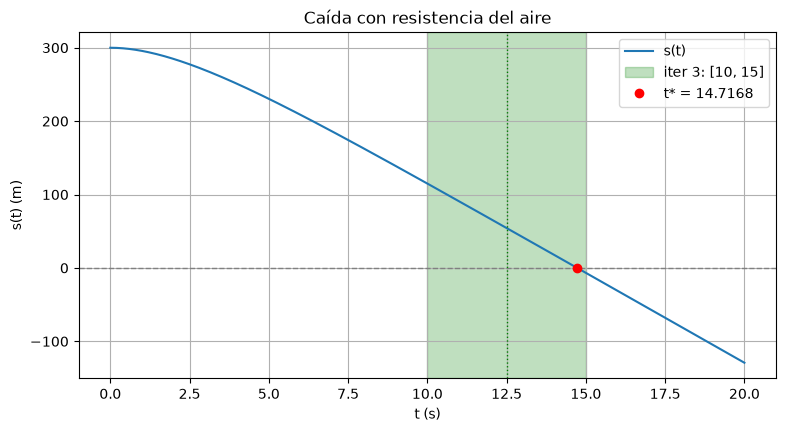

In [24]:


def biseccion(f, a, b, TOL=1e-2, N0=100):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a+(b-a)/2                                 # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a,b,p))                        # COMPLETE: (a, b, p)
        if FP == 0 or (b-a)/2<TOL:                          # COMPLETE: parada por TOL
            return p, historia, i
        i = i + 1
        if FA * FP > 0:
            a = p
            FA = FP                                   # COMPLETE: mover a y FA
        else:
            b = p                                   # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")

g = 9.81
s0, m, k = 300.0, 0.25, 0.1

def s(t:float)->float:
    return s0 - (m * g / k) * t + (m ** 2 * g / k ** 2) * (1 - np.exp(-k * t / m))

t_star, historia, i = biseccion(s, 0.0, 20.0)
print(f"{i}, {historia}")
import numpy as np
import matplotlib.pyplot as plt

def graficar(t_star, historia, k_iteracion=None, archivo="caida.png"):
    """Dibuja s(t). Si k_iteracion no es None, resalta el intervalo [a, b]
    de esa iteración (1-based) y su punto medio p."""
    t = np.linspace(0, 20, 400)
    plt.figure(figsize=(9, 4.5))
    plt.plot(t, s(t), label="s(t)")
    plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    if k_iteracion is not None:
        a, b, p = historia[k_iteracion - 1]
        plt.axvspan(a, b, color="green", alpha=0.25,
                    label=f"iter {k_iteracion}: [{a:.4g}, {b:.4g}]")
        plt.axvline(p, color="green", linestyle=":", linewidth=1)
    plt.plot(t_star, 0, "ro", label=f"t* = {t_star:.4f}")
    plt.xlabel("t (s)")
    plt.ylabel("s(t) (m)")
    plt.title("Caída con resistencia del aire")
    plt.legend()
    plt.grid(True)
    plt.savefig(archivo, dpi=150)
    plt.show()

graficar(t_star, historia, k_iteracion=3)




